# Karachi Community Health Intelligence System: Statistical Analysis & Modeling

## 1. Environment Setup & Data Loading

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Set global style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True, 'figure.dpi': 300})

# Load the cleaned dataset
df = pd.read_excel('../data/Karachi Community Health Surveillance Analytics System_cleaned.xlsx')
print("Dataset loaded successfully. Shape:", df.shape)

Dataset loaded successfully. Shape: (472, 40)


## 2. Test 1: Gender vs. Nutritional Status (Chi-Square Test)

In [2]:
# Create contingency table for Gender vs Nutritional Scale
contingency_gender_bmi = pd.crosstab(df['gender'], df['nutritional_scale'])
print("--- Contingency Table: Gender vs Nutritional Scale ---")
display(contingency_gender_bmi)

# Perform Chi-Square Test of Independence
chi2, p_val, dof, expected = chi2_contingency(contingency_gender_bmi)

print("\n--- Chi-Square Test Results ---")
print(f"Chi2 Statistic: {chi2:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"Degrees of Freedom: {dof}")

if p_val < 0.05:
    print("Conclusion: Statistically significant association between gender and nutritional status (Reject Null Hypothesis).")
else:
    print("Conclusion: No statistically significant association between gender and nutritional status.")

--- Contingency Table: Gender vs Nutritional Scale ---


nutritional_scale,normal weight,obese,overweight,underweight
gender,,,,
female,56,6,29,84
male,138,8,18,133



--- Chi-Square Test Results ---
Chi2 Statistic: 18.2713
p-value: 0.0004
Degrees of Freedom: 3
Conclusion: Statistically significant association between gender and nutritional status (Reject Null Hypothesis).


## 3. Test 2: Education vs. Nutritional Status (Chi-Square Test)

In [3]:
# Create contingency table for Educational Years vs Nutritional Scale
contingency_edu_bmi = pd.crosstab(df['educational_years'], df['nutritional_scale'])

# Perform Chi-Square Test
chi2_edu, p_edu, dof_edu, expected_edu = chi2_contingency(contingency_edu_bmi)

print("--- Chi-Square Test Results: Education vs Nutritional Status ---")
print(f"Chi2 Statistic: {chi2_edu:.4f}")
print(f"p-value: {p_edu:.4f}")

if p_edu < 0.05:
    print("Conclusion: Education significantly influences nutritional outcomes.")
else:
    print("Conclusion: No significant association detected between education years and nutritional status.")

--- Chi-Square Test Results: Education vs Nutritional Status ---
Chi2 Statistic: 33.2381
p-value: 0.8309
Conclusion: No significant association detected between education years and nutritional status.


## 4. Test 3: Household Income vs. BMI Category (Chi-Square & Boxplot)

--- Chi-Square Test Results: Income vs Nutritional Status ---
Chi2 Statistic: 126.1547
p-value: 0.6270



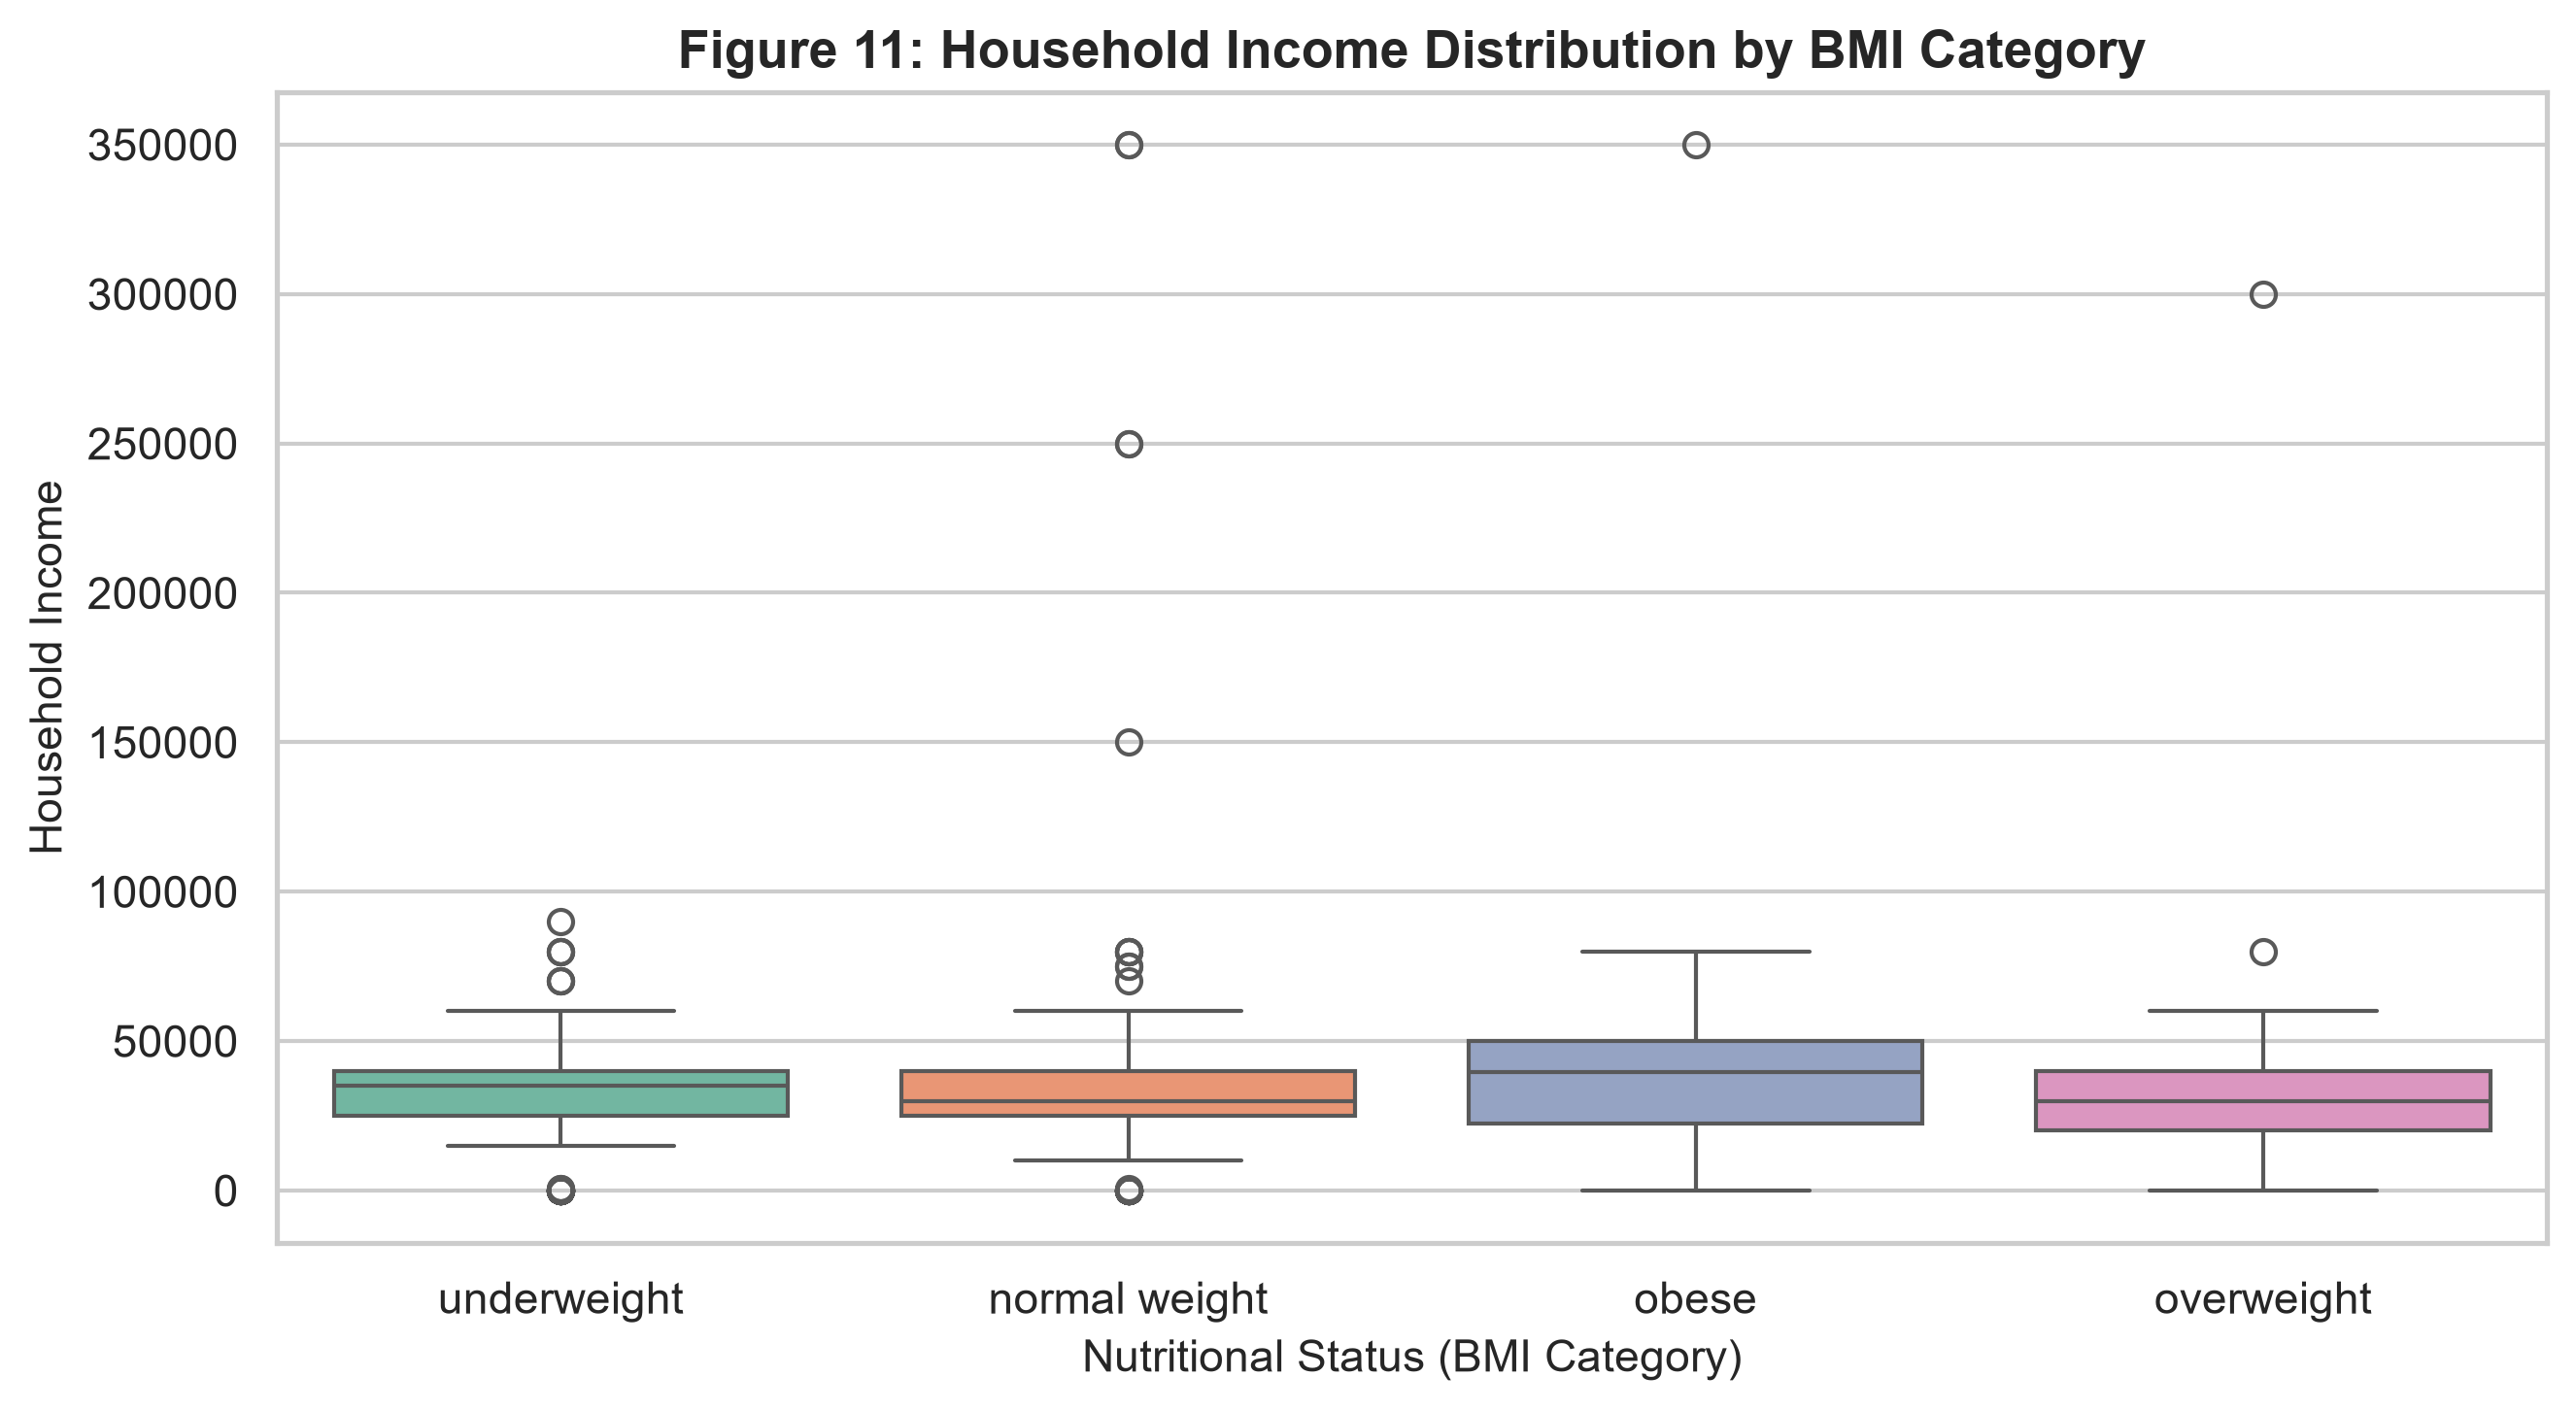

In [4]:
# Chi-Square Test for Income vs Nutritional Scale (binning income or using crosstab)
contingency_income_bmi = pd.crosstab(df['household_income'], df['nutritional_scale'])
chi2_inc, p_inc, dof_inc, expected_inc = chi2_contingency(contingency_income_bmi)

print("--- Chi-Square Test Results: Income vs Nutritional Status ---")
print(f"Chi2 Statistic: {chi2_inc:.4f}")
print(f"p-value: {p_inc:.4f}\n")

# Visual: Income Distribution across BMI categories (Boxplot)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='nutritional_scale', y='household_income', palette='Set2', hue='nutritional_scale', legend=False)
plt.title('Figure 11: Household Income Distribution by BMI Category', fontsize=13, fontweight='bold')
plt.xlabel('Nutritional Status (BMI Category)', fontsize=11)
plt.ylabel('Household Income', fontsize=11)
os.makedirs('../visuals', exist_ok=True)
plt.savefig('../visuals/fig11_income_by_bmi.png', bbox_inches='tight')
plt.show()

## 5. Test 4: Age vs. BMI (Pearson Correlation & Regplot)

--- Pearson Correlation: Age vs BMI ---
Correlation Coefficient (r): -0.1963
p-value: 0.0000


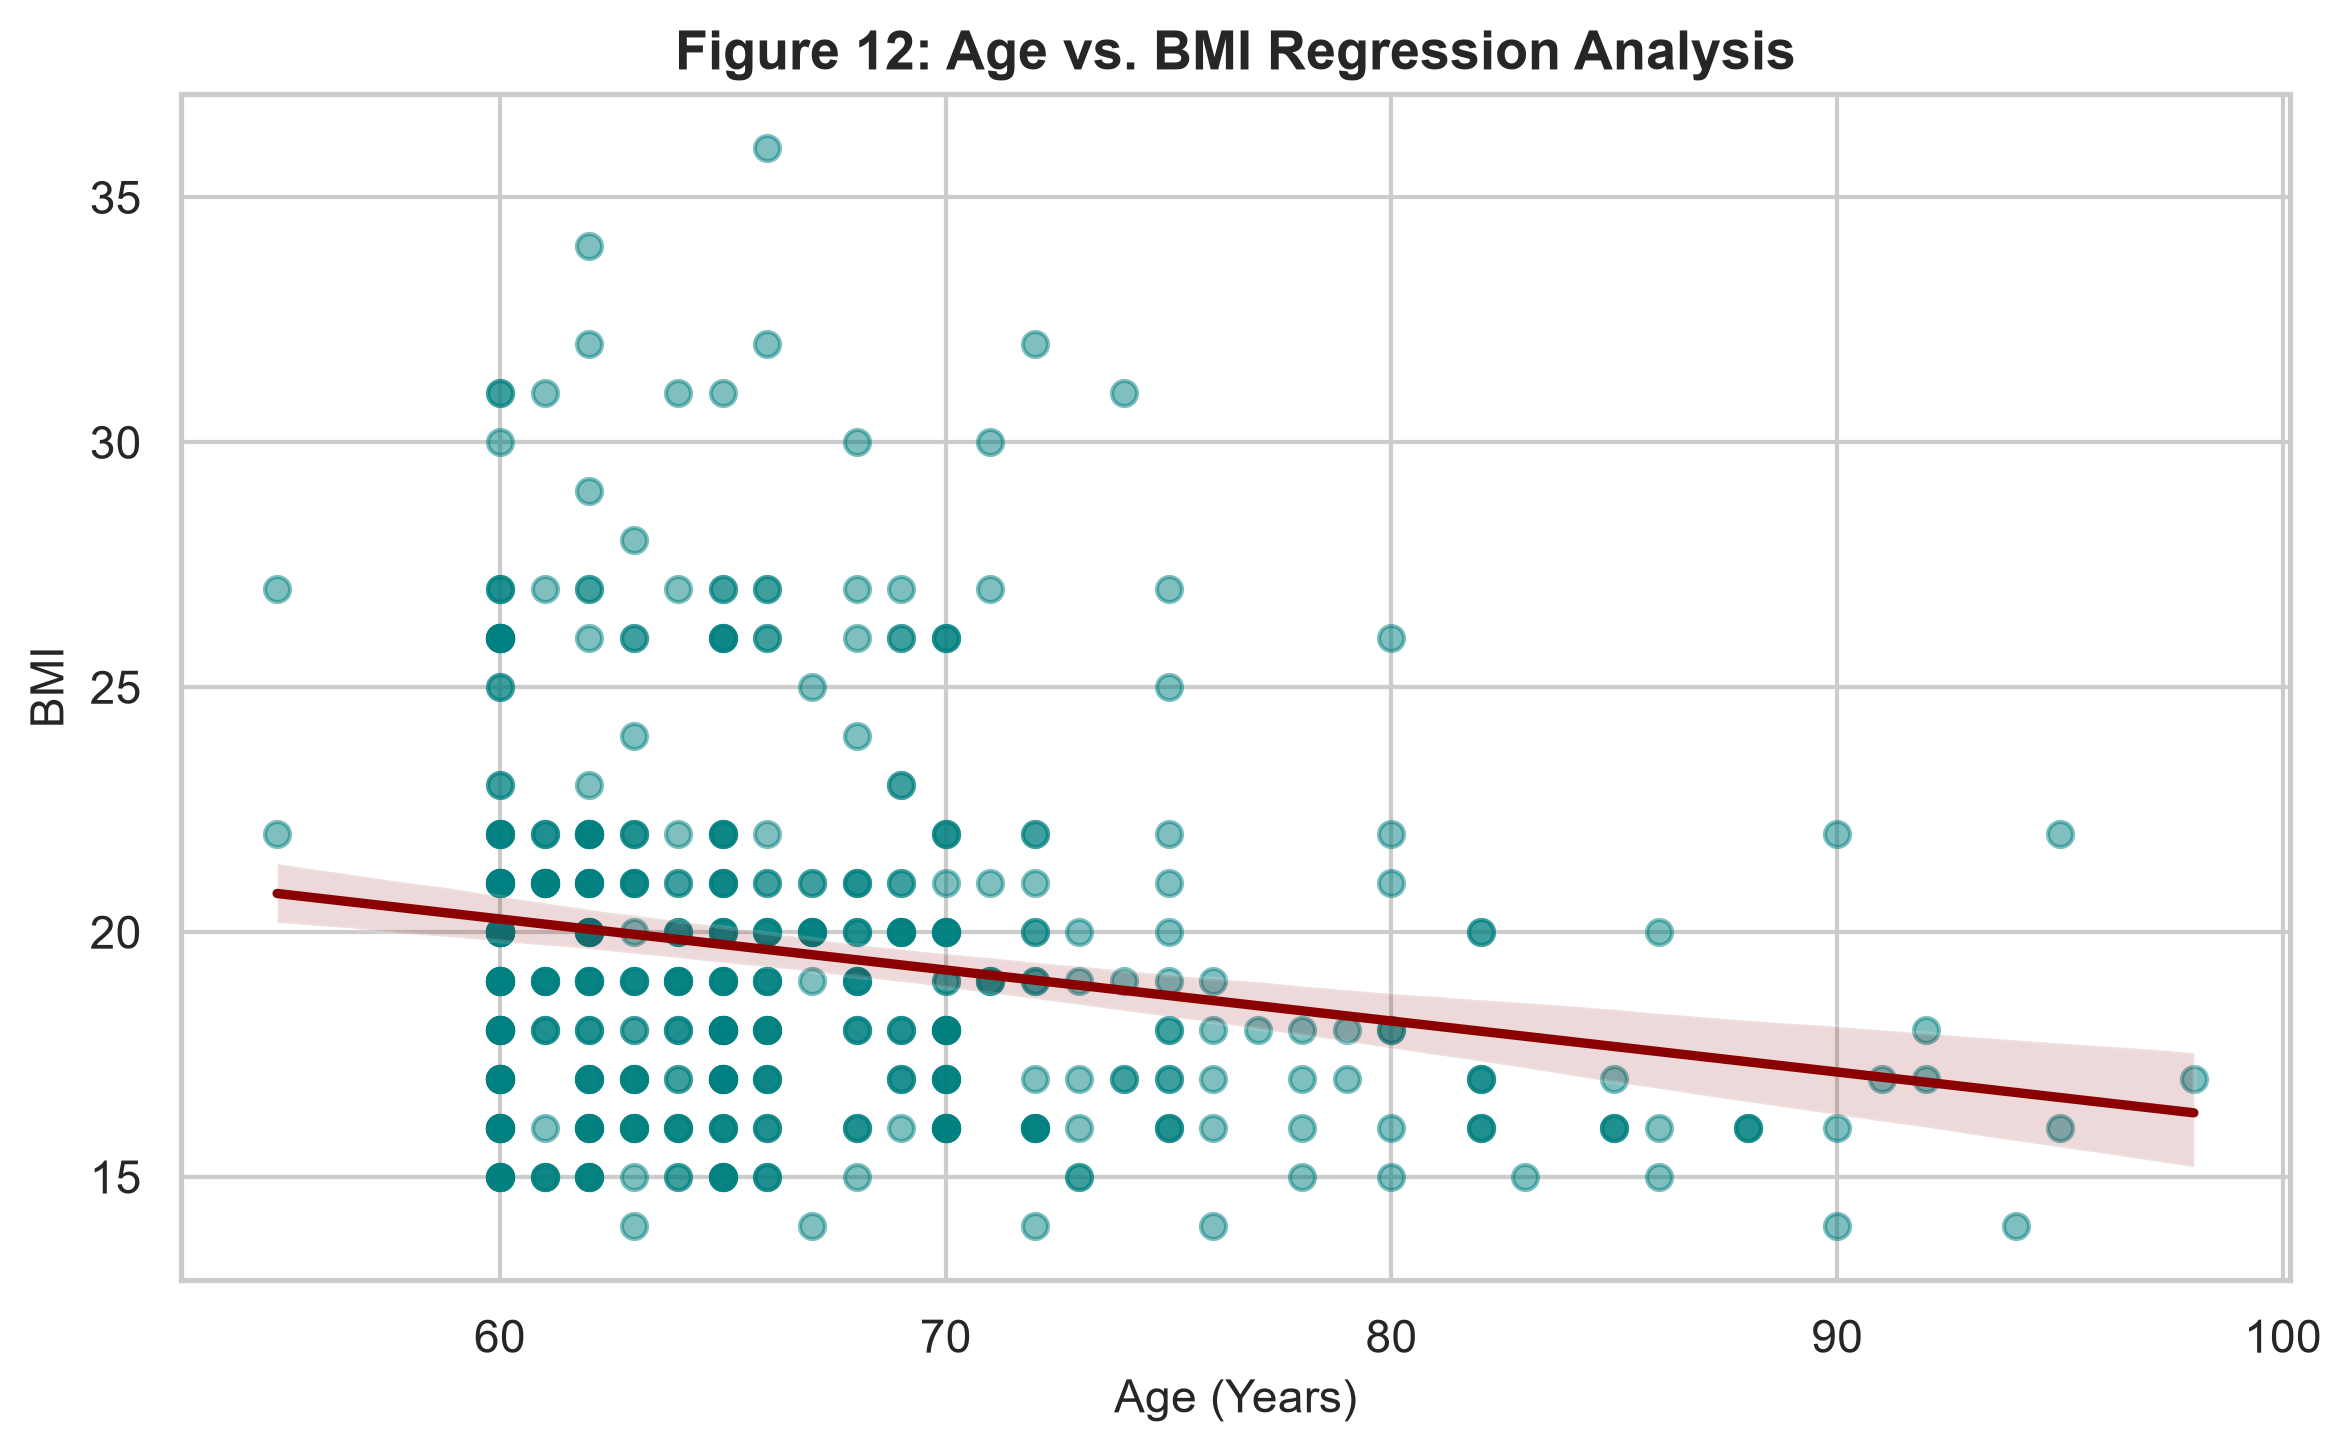

In [5]:
# Pearson Correlation
corr, p_corr = pearsonr(df['age'], df['bmi'])

print("--- Pearson Correlation: Age vs BMI ---")
print(f"Correlation Coefficient (r): {corr:.4f}")
print(f"p-value: {p_corr:.4f}")

# Visual: Regression Plot
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='age', y='bmi', scatter_kws={'alpha': 0.5, 'color': 'teal'}, line_kws={'color': 'darkred'})
plt.title('Figure 12: Age vs. BMI Regression Analysis', fontsize=13, fontweight='bold')
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('BMI', fontsize=11)
plt.savefig('../visuals/fig12_age_vs_bmi_regplot.png', bbox_inches='tight')
plt.show()

## 6. Test 5: Smoking Status vs. Health Status (Chi-Square Test)

In [6]:
# Contingency table for Smoking Status vs Health Status
contingency_smoke_health = pd.crosstab(df['smoking_status'], df['health_status'])
print("--- Contingency Table: Smoking Status vs Health Status ---")
display(contingency_smoke_health)

chi2_sh, p_sh, dof_sh, expected_sh = chi2_contingency(contingency_smoke_health)

print("\n--- Chi-Square Test Results ---")
print(f"Chi2 Statistic: {chi2_sh:.4f}")
print(f"p-value: {p_sh:.4f}")

if p_sh < 0.05:
    print("Conclusion: Smoking status has a statistically significant relationship with self-reported health status.")
else:
    print("Conclusion: No significant association found between smoking status and health status.")

--- Contingency Table: Smoking Status vs Health Status ---


health_status,excellent,fair,good,poor,very good
smoking_status,,,,,
current smoker,52,16,39,3,22
former smoker,30,16,54,12,27
never smoked a cigarette,13,23,121,6,38



--- Chi-Square Test Results ---
Chi2 Statistic: 69.6669
p-value: 0.0000
Conclusion: Smoking status has a statistically significant relationship with self-reported health status.


## 7. Predictive Modeling: Logistic Regression for Malnutrition Risk

In [8]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

# 1. Create binary target variable (1 = Malnourished / Underweight [BMI < 18.5], 0 = Otherwise)
df['is_malnourished'] = (df['bmi'] < 18.5).astype(int)

# 2. Select Features and Target
features = [
    'age',
    'gender',
    'household_income',
    'educational_years',
    'smoking_status',
    'physical_activity',
]
X = df[features].copy()
y = df['is_malnourished']

# 3. Handle Categorical Encoding using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

# 4. Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Scale Continuous Numerical Features (Fixes the Convergence Warning)
continuous_cols = ['age', 'educational_years', 'household_income']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(
    X_train[continuous_cols]
)
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

# 6. Fit Logistic Regression Model with increased max_iter
log_model = LogisticRegression(max_iter=5000, random_state=42)
log_model.fit(X_train_scaled, y_train)

# 7. Predictions & Evaluation
y_pred = log_model.predict(X_test_scaled)

print('--- Logistic Regression Model Performance (Scaled) ---')
print(f'Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n')
print('Classification Report:')
print(classification_report(y_test, y_pred))

# 8. Feature Coefficients Summary
coef_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': log_model.coef_[0],
}).sort_values(by='Coefficient', ascending=False)

print('\n--- Feature Coefficients ---')
display(coef_df)

--- Logistic Regression Model Performance (Scaled) ---
Accuracy Score: 0.6211

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.79      0.69        52
           1       0.62      0.42      0.50        43

    accuracy                           0.62        95
   macro avg       0.62      0.60      0.60        95
weighted avg       0.62      0.62      0.61        95


--- Feature Coefficients ---


,Feature,Coefficient
5,smoking_status_never smoked a cigarette,0.793226
0,age,0.527508
4,smoking_status_former smoker,0.457976
2,educational_years,0.099330
8,physical_activity_sometimes,0.068625
6,physical_activity_occasionally,0.041421
3,gender_male,0.016974
1,household_income,-0.066565
7,physical_activity_routinely,-0.292737


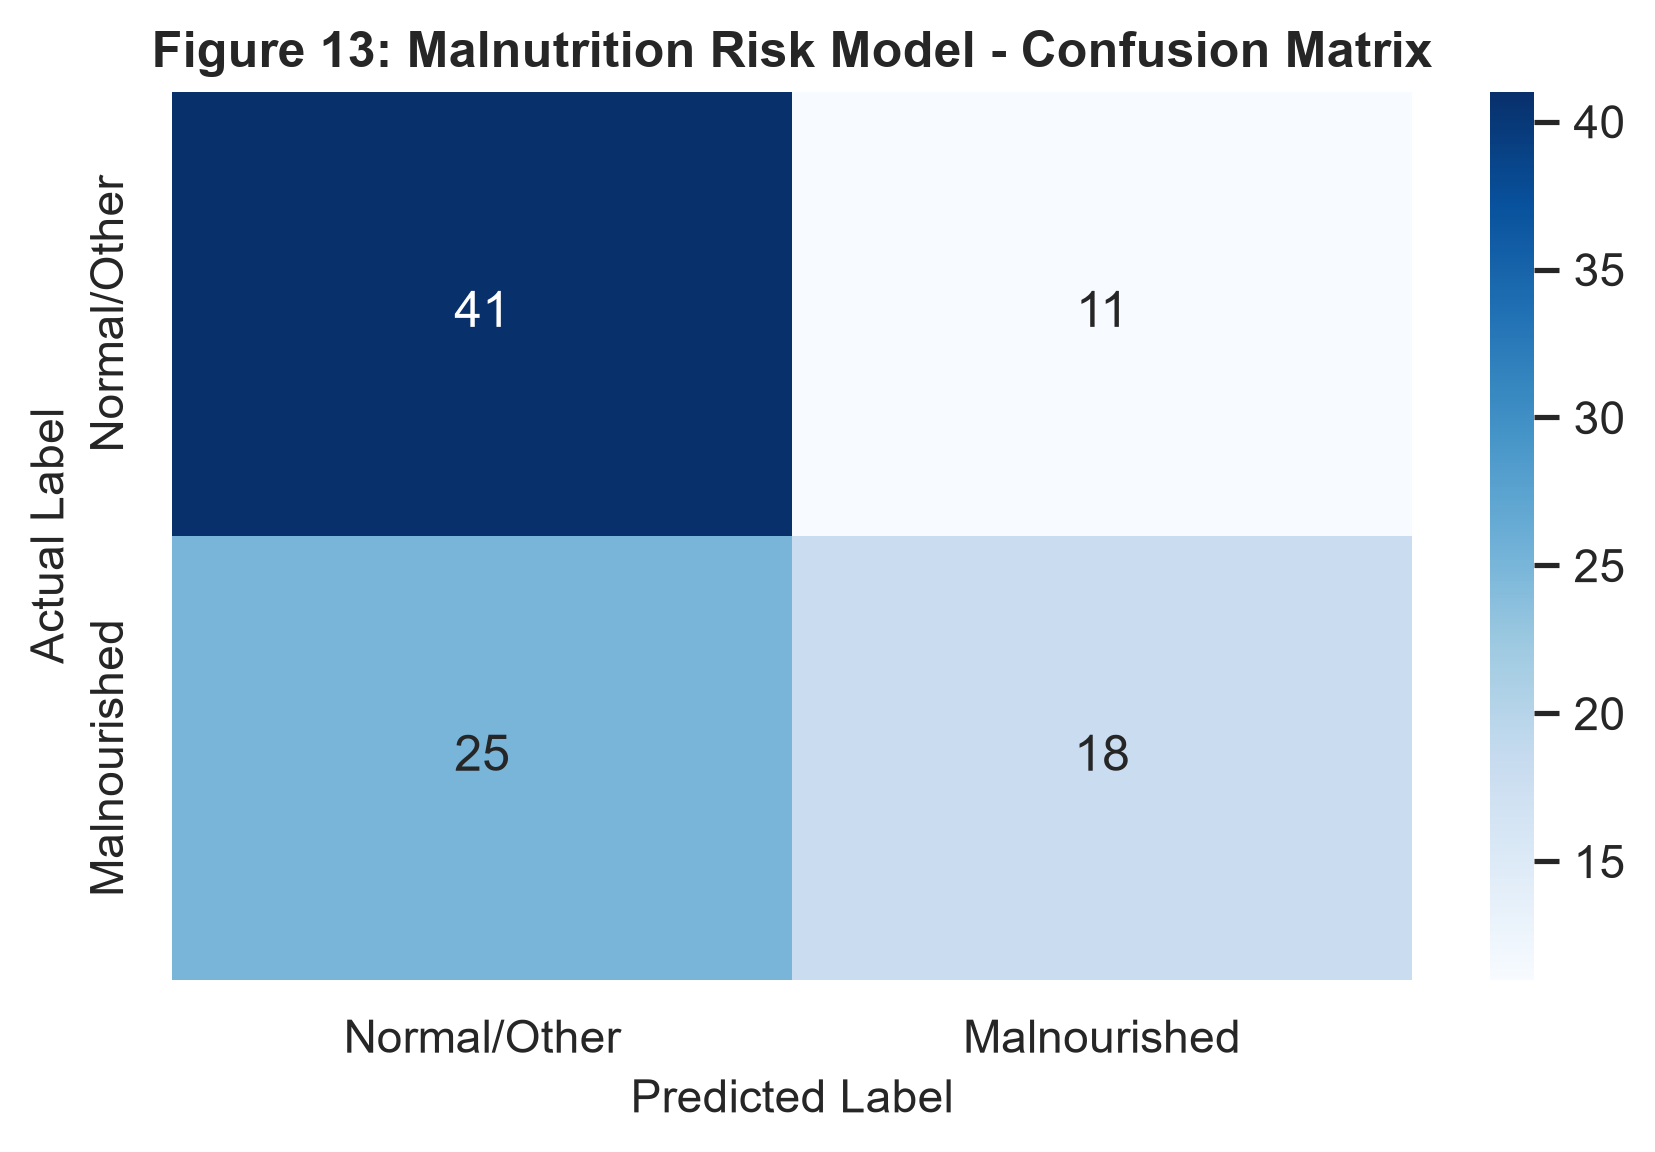

In [9]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal/Other', 'Malnourished'],
    yticklabels=['Normal/Other', 'Malnourished'],
)
plt.title(
    'Figure 13: Malnutrition Risk Model - Confusion Matrix',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('Actual Label', fontsize=11)
plt.savefig('../visuals/fig13_confusion_matrix.png', bbox_inches='tight')
plt.show()